# 1. December Chart Inputs

In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [97]:
dec_data = pd.read_csv("december-chart-inputs.csv")

In [98]:
dec_data.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,01-12-2025,851.82
1,Lexington,Fort Wayne,360,Dry Van,32000,02-12-2025,833.71
2,Lexington,Fort Wayne,360,Dry Van,32000,03-12-2025,834.16
3,Lexington,Fort Wayne,360,Dry Van,32000,04-12-2025,835.01
4,Lexington,Fort Wayne,360,Dry Van,32000,05-12-2025,835.03


In [99]:
pd.set_option('display.max_rows', None)

dec_data

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,01-12-2025,851.82
1,Lexington,Fort Wayne,360,Dry Van,32000,02-12-2025,833.71
2,Lexington,Fort Wayne,360,Dry Van,32000,03-12-2025,834.16
3,Lexington,Fort Wayne,360,Dry Van,32000,04-12-2025,835.01
4,Lexington,Fort Wayne,360,Dry Van,32000,05-12-2025,835.03
5,Lexington,Fort Wayne,360,Dry Van,32000,06-12-2025,835.03
6,Lexington,Fort Wayne,360,Dry Van,32000,07-12-2025,834.92
7,Lexington,Fort Wayne,360,Dry Van,32000,08-12-2025,833.70
8,Lexington,Fort Wayne,360,Dry Van,32000,09-12-2025,834.29
9,Lexington,Fort Wayne,360,Dry Van,32000,10-12-2025,834.64


In [100]:
dec_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pickup          31 non-null     object 
 1   delivery        31 non-null     object 
 2   distance        31 non-null     int64  
 3   equipment       31 non-null     object 
 4   weight          31 non-null     int64  
 5   date            31 non-null     object 
 6   predicted_rate  31 non-null     float64
dtypes: float64(1), int64(2), object(4)
memory usage: 1.8+ KB


In [101]:
dec_data.describe()

,distance,weight,predicted_rate
count,31.0,31.0,31.000000
mean,360.0,32000.0,836.307097
std,0.0,0.0,3.093783
min,360.0,32000.0,833.700000
25%,360.0,32000.0,835.030000
50%,360.0,32000.0,835.650000
75%,360.0,32000.0,836.965000
max,360.0,32000.0,851.820000


In [102]:
print("Shape (Rows, Columns):", dec_data.shape)

Shape (Rows, Columns): (31, 7)


In [103]:
print("Columns:", dec_data.columns.tolist())

Columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


In [104]:
print("\nMissing Values:\n", dec_data.isnull().sum())


Missing Values:
 pickup            0
delivery          0
distance          0
equipment         0
weight            0
date              0
predicted_rate    0
dtype: int64


In [105]:
# Group by 'pickup' and get the top 5 rows for each location
top_5_per_pickup = dec_data.groupby('pickup').head(5)

# Display all columns and rows clearly
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

top_5_per_pickup

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,01-12-2025,851.82
1,Lexington,Fort Wayne,360,Dry Van,32000,02-12-2025,833.71
2,Lexington,Fort Wayne,360,Dry Van,32000,03-12-2025,834.16
3,Lexington,Fort Wayne,360,Dry Van,32000,04-12-2025,835.01
4,Lexington,Fort Wayne,360,Dry Van,32000,05-12-2025,835.03


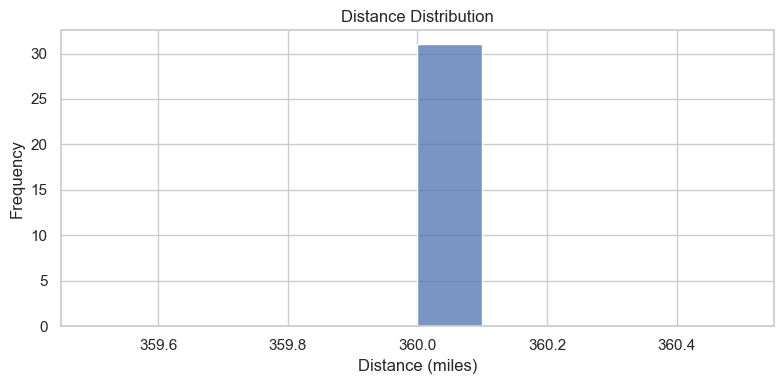

In [106]:
# Distance
plt.figure(figsize=(8, 4))
sns.histplot(data=dec_data, x="distance", bins=10)
plt.title("Distance Distribution")
plt.xlabel("Distance (miles)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()



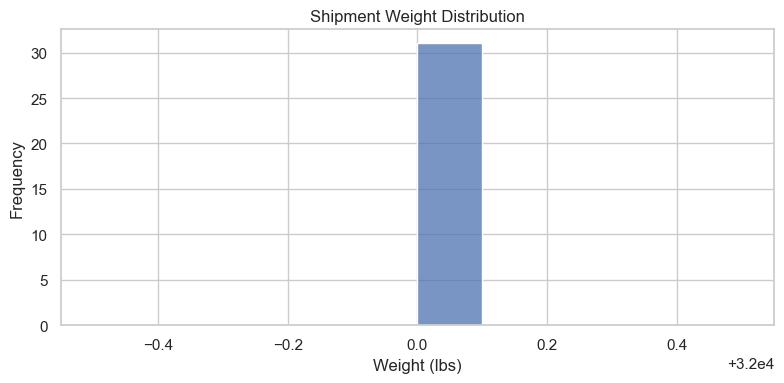

In [107]:
# Weight
plt.figure(figsize=(8, 4))
sns.histplot(data=dec_data, x="weight", bins=10)
plt.title("Shipment Weight Distribution")
plt.xlabel("Weight (lbs)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()



# 2. validation_predictions

In [108]:
vali_pre = pd.read_csv("validation_predictions.csv")

In [109]:
# IQR method: flag potential outliers
Q1 = df["predicted_rate"].quantile(0.25)
Q3 = df["predicted_rate"].quantile(0.75)
IQR = Q3 - Q1


In [110]:
IQR

2139.9925

In [111]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [112]:
lower_bound

-1923.4437499999995

In [113]:
upper_bound

6636.526249999999

In [114]:
outliers = df[
    (df["predicted_rate"] < lower_bound) |
    (df["predicted_rate"] > upper_bound)
]
outliers

,load_id,predicted_rate,rate_category
503,TE-000504,7395.95,"Above $4,000"
519,TE-000520,8064.51,"Above $4,000"
936,TE-000937,6652.24,"Above $4,000"
1168,TE-001169,7181.29,"Above $4,000"
1953,TE-001954,6717.73,"Above $4,000"
2197,TE-002198,7534.71,"Above $4,000"
3143,TE-003144,9274.33,"Above $4,000"
3227,TE-003228,7216.21,"Above $4,000"
3244,TE-003245,7127.66,"Above $4,000"
3466,TE-003467,7201.47,"Above $4,000"


In [115]:
print("Potential outliers:", len(outliers))
display(outliers.head(10))

Potential outliers: 39


,load_id,predicted_rate,rate_category
503,TE-000504,7395.95,"Above $4,000"
519,TE-000520,8064.51,"Above $4,000"
936,TE-000937,6652.24,"Above $4,000"
1168,TE-001169,7181.29,"Above $4,000"
1953,TE-001954,6717.73,"Above $4,000"
2197,TE-002198,7534.71,"Above $4,000"
3143,TE-003144,9274.33,"Above $4,000"
3227,TE-003228,7216.21,"Above $4,000"
3244,TE-003245,7127.66,"Above $4,000"
3466,TE-003467,7201.47,"Above $4,000"


In [116]:
top_10 = df.nlargest(10, "predicted_rate")

display(top_10)

,load_id,predicted_rate,rate_category
3143,TE-003144,9274.33,"Above $4,000"
10037,TE-010038,9070.05,"Above $4,000"
5908,TE-005909,9062.99,"Above $4,000"
6223,TE-006224,9031.75,"Above $4,000"
4744,TE-004745,8336.23,"Above $4,000"
519,TE-000520,8064.51,"Above $4,000"
6455,TE-006456,8023.75,"Above $4,000"
8961,TE-008962,7814.75,"Above $4,000"
3893,TE-003894,7730.81,"Above $4,000"
11104,TE-011105,7709.12,"Above $4,000"


<Axes: xlabel='predicted_rate', ylabel='load_id'>

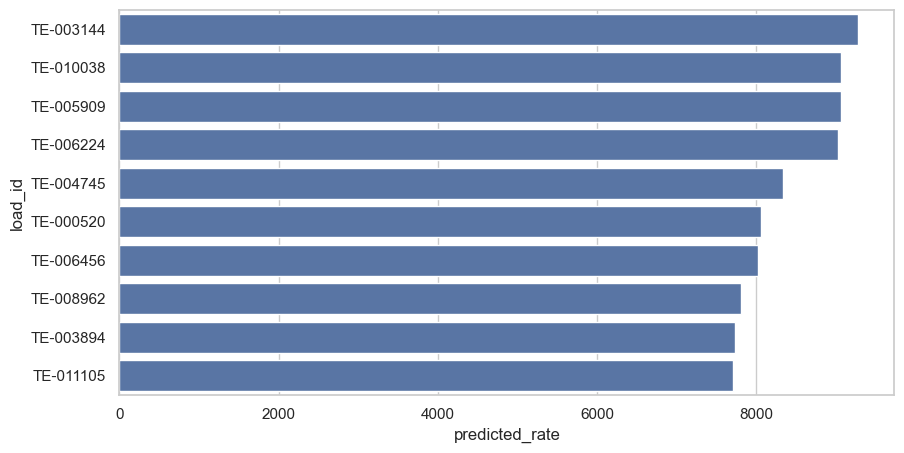

In [117]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_10,
    x="predicted_rate",
    y="load_id"
)